Do not immediately answer my question. First identify what I'm actually trying to solve. Ask me the three most important questions that would help you give me a much better answer.

I'm going to share an idea with you. Your job isn't to agree with me. Find the 5 biggest weaknesses, challenge my assumptions, identify what I'm overlooking, and tell me what could make this fail.

I want to achieve [result]. Work backward from desired outcome. Identify the exact steps, skills tools, decisions, and milestones required to get there. Explain the most efficient path.

As a top 1% expert in [field]. Evaluate my current approach, identify what beginners misunderstand, explain what experienced professionals do differently, and show me to think at an advanced level.

Act as my expert advisor. Here is my situation: [context]. Here is what I want to achieve: [goal]. Identify my biggest leverage point.

# Problem 10.5: same five-step protocol

**Answer: N ≈ 9.4 × 10⁴ cycles** to grow the crack from a/t = 0.1 to 0.8. The crack's aspect ratio a/2c rises from 0.10 and levels off around 0.37. The program is `surface_crack_growth.py`, and the contour plot with the aspect-ratio history is `surface_crack_contours.png`.

---

## Prompt 1: What you're actually solving, and the three key questions

**What you're solving.** This is the most realistic problem so far. The crack has **two growth directions**: depth a, controlled by the deepest point (φ = 90°), and half-length c, controlled by the surface point (φ = 0°). K differs at the two points, so they grow at different rates and **the crack shape changes as it grows**. You're tracking two coupled quantities (a and c) together with N, and finding the shape the crack evolves toward.

**The three questions I'd ask, and the answers I'm assuming:**
1. *Do you need Table A9.1 exactly?* I don't have the table itself. I used the **Newman–Raju equations** for membrane loading, the empirical fit to the same finite-element results that surface-crack tables like A9.1 are built from. They should agree within a few percent. If your grader wants the table, replace one function with a table interpolation (marked in the code).
2. *Is "stress amplitude 200 MPa" the range?* I treated it as **Δσ = 200 MPa**, consistent with Problem 10.1. If it literally means amplitude, Δσ = 400 MPa and N is 8× smaller, about 11,800 cycles.
3. *Program or spreadsheet?* The problem says program, so I wrote one in Python.

---

## Prompt 2: The five biggest weaknesses of the "obvious" approach

1. **Using a single K and freezing the shape.** Growing a and c with the same ΔK, or holding a/c constant, misses the whole point. The shape change is the answer to the last question in the problem.
2. **Getting φ backward.** In the Newman–Raju convention, **φ = 0° is the surface point** (it controls c) and **φ = 90° is the deepest point** (it controls a). Swapping them makes the crack evolve the wrong way.
3. **Forgetting Q.** K = σ√(πa/Q)·F. The shape factor Q = 1 + 1.464(a/c)^1.65 changes as a/c changes, so it must be recomputed at every step.
4. **Taking steps that are too big.** Over each step a and c affect each other. Coarse explicit steps drift away from the true growth path. Use a proper ODE solver, or a midpoint (RK2) scheme with small steps, and check that the result converges.
5. **Ignoring where the model stops being valid.** The ellipse assumption and the K solution become less accurate near a/t → 1, where the crack approaches breakthrough to the back face. At that point the crack becomes a through-crack, which is a different problem.

---

## Prompt 3: Fully worked solution

### Work backward from the goal
You need N and the crack shape at the five a/t values. Both come from integrating the coupled growth rates, which need ΔK at both crack-front points, which need F(a/c, a/t, φ) and Q.

### Step 1: The K solution (Newman–Raju, membrane loading, a/c ≤ 1)

$$\Delta K = \Delta\sigma\sqrt{\frac{\pi a}{Q}}\;F, \qquad F = \left[M_1 + M_2\left(\tfrac{a}{t}\right)^2 + M_3\left(\tfrac{a}{t}\right)^4\right] g\, f_\phi\, f_w$$

The terms are:
- Q = 1 + 1.464(a/c)^1.65
- M₁ = 1.13 − 0.09(a/c)
- M₂ = −0.54 + 0.89/(0.2 + a/c)
- M₃ = 0.5 − 1/(0.65 + a/c) + 14(1 − a/c)²⁴
- g = 1 + [0.1 + 0.35(a/t)²](1 − sin φ)²
- f_φ = [(a/c)² cos²φ + sin²φ]^¼
- f_w = 1, because c ≪ W

### Step 2: The coupled growth equations
- da/dN = C·ΔK_A³ at the deepest point A (φ = 90°)
- dc/dN = C·ΔK_C³ at the surface point C (φ = 0°)

**The efficient trick is to use a as the independent variable.** That gives two ordinary differential equations:

$$\frac{dc}{da} = \left(\frac{\Delta K_C}{\Delta K_A}\right)^3, \qquad \frac{dN}{da} = \frac{1}{C\,\Delta K_A^3}$$

Integrate both from a₀ to a_f. The program does this with an ODE solver.

### Step 3: Initial conditions
- t = 25.4 mm and a₀ = 0.1t = 2.54 mm
- a/2c = 0.1, so 2c₀ = 25.4 mm (c₀ = 12.7 mm) and a/c = 0.2
- The final depth is 0.8t = 20.32 mm

### Results

| a/t | a (mm) | 2c (mm) | a/2c | ΔK_A | ΔK_C | N (cycles) |
|---|---|---|---|---|---|---|
| 0.1 | 2.54 | 25.4 | 0.100 | 19.2 | 9.5 | 0 |
| 0.2 | 5.08 | 26.5 | 0.192 | 25.1 | 17.3 | 33,700 |
| 0.4 | 10.16 | 32.2 | 0.316 | 31.7 | 29.1 | 66,100 |
| 0.6 | 15.24 | 42.0 | 0.363 | 38.0 | 39.7 | 84,000 |
| 0.8 | 20.32 | 55.2 | 0.368 | 45.5 | 51.7 | **94,400** |

ΔK values are in MPa√m.

**Verification:** a hand-written 50-step midpoint loop agrees with the ODE solver to within 0.05%.

### What happens to a/2c
1. **At the start, the crack grows mainly in depth.** A long, shallow crack (a/2c = 0.1) has ΔK at the deepest point about **twice** the surface value (19.2 vs 9.5). Since growth goes as ΔK³, it deepens about 8× faster than it lengthens. Between a/t = 0.1 and 0.2, 2c barely changes (25.4 → 26.5 mm) while a doubles.
2. **The crack becomes more rounded,** and ΔK_A and ΔK_C converge.
3. **It levels off at about a/2c ≈ 0.37 (a/c ≈ 0.73).** Around a/t ≈ 0.5–0.6, ΔK_C catches up with and then passes ΔK_A. The surface point then grows slightly faster, which holds the shape steady and flattens it slightly at the end.

**The physical idea: a crack evolves toward a "preferred" shape where K is roughly uniform along the front**, whatever shape it started with. A free surface and a back face shift where that preferred shape lies, which is why it ends up around a/c ≈ 0.7–0.8 rather than a perfect semicircle.

---

## Prompt 4: Expert evaluation

**Beginners misunderstand:**
- **The initial shape doesn't matter much for the final shape, but it matters a lot for life.** Cracks starting at different aspect ratios converge toward the same shape. A long, shallow initial flaw still costs life, though, because its deepest point has a high ΔK from the start.
- **Most life is spent early, again.** About **36%** of the life goes into the first doubling of depth (a/t from 0.1 to 0.2). That's the same lesson as in 10.1, 10.2 and 10.4.
- **The governing point changes.** Early on the deepest point controls growth. Later the surface point has the higher ΔK. A one-point analysis gets one of those phases wrong.

**What professionals do differently:**
- **Account for surface closure.** Newman and Raju recommend growing the surface point with **(0.9·ΔK_C)**, because material near the surface is in plane stress and shows more crack closure (the mechanism from 10.3). That keeps the crack somewhat deeper and narrower, and the program can include it with a one-line change.
- **Model breakthrough.** As a/t → 1, the crack penetrates the back face and becomes a through-crack. That moment is critical in pressure vessels and pipes, where it's the basis of leak-before-break: the vessel leaks detectably before it bursts. NASGRO and AFGROW switch K solutions automatically at breakthrough.
- **Check K_max against toughness at both points.** At the end, ΔK_C ≈ 52 MPa√m. For the 10.2 steel (K_Ic = 25), fracture would occur long before a/t = 0.8, and **it would start at the surface point**, not the deepest one.
- **Use more points or a weight function** for non-uniform stress such as bending or weld residual stress. Two points is a standard engineering approximation, while 3-D finite-element analysis or multi-point methods track non-elliptical fronts.

**How to think at an advanced level:** this problem is a **two-dimensional dynamical system** with a stable attractor. The ratio ΔK_C/ΔK_A acts as a restoring force: if the crack is too shallow, the deepest point outruns the surface, and if it's too round, the surface outruns the depth. Ask where that ratio equals 1 and you can predict the preferred shape before running any code.

---

## Prompt 5: Your biggest leverage point

**The leverage point is the ratio ΔK_C / ΔK_A, the variation of K along the crack front.**

1. **It sets the shape.** dc/da = (ΔK_C/ΔK_A)³ determines every contour in the plot.
2. **It sets which point controls life and fracture,** shifting from depth to surface as the crack grows.
3. **It generalizes the previous problems.** Problems 10.1–10.4 treated K as one number. Real cracks have a K distribution along the front, and this problem is your introduction to thinking about that.

Combine it with the numerical loop from 10.4, which this problem extends to two variables, and you have the core of every professional crack growth code.

**Milestone for full understanding:**
1. Start from a/2c = 0.5 (a semicircle) and predict, before running the program, whether the crack becomes deeper or shallower. (It flattens toward about 0.37.)
2. Add the 0.9 surface-closure factor and explain why the final a/2c goes up.
3. Change the loading to bending and explain why the crack becomes much shallower. Under bending the stress decreases with depth, so ΔK_A falls as the crack deepens.

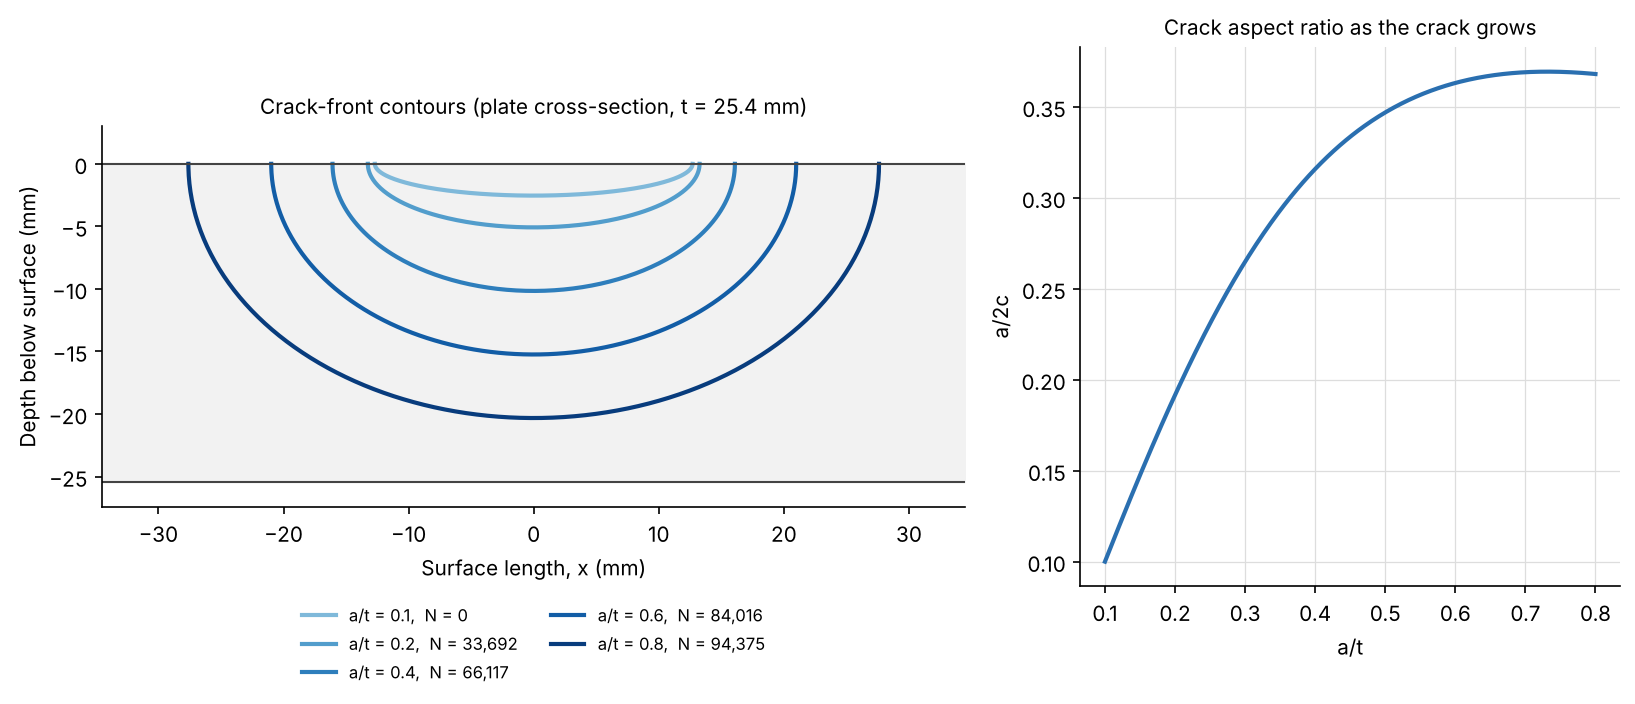